In [1]:
import pandas as pd
import numpy as np
import regex as re
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv(r'D:\Download\doc\SK_WIDIASIH\dataset_kompas\databersih\data_motifkejahatan.csv')

In [12]:
df.head()

,judul_berita,isi_berita,text_clean,label_kriminal,label_krim_gabungan,jenis_kriminal,prediksi_jenis_dt,motif_kejahatan,prediksi_motif_dt,hubungan_pelaku_korban
0,Bocah yang Jasadnya Terbungkus Sarung Tewas Di...,"JAKARTA, KOMPAS.com - Pasangan pengemis bernam...",pasangan pengemis bernama sinta dewi 22 aidil ...,True,1,Pembunuhan,Pembunuhan,"Dendam, Emosi & Konflik","Dendam, Emosi & Konflik",Saling Kenal
1,Orangtua Bocah Tewas dalam Sarung Sering Aniay...,"JAKARTA, KOMPAS.com - Sinta Dewi (22) dan Aidi...",sinta dewi 22 aidil zacky rahman 19 pengemis d...,True,1,Penganiayaan & Kekerasan,Penganiayaan & Kekerasan,"Dendam, Emosi & Konflik","Dendam, Emosi & Konflik",Tidak Kenal/Tidak Diketahui
2,Orangtua Bocah Tewas dalam Sarung Aniaya Anakn...,"JAKARTA, KOMPAS.com - Dua pengemis bernama Sin...",pengemis bernama sinta dewi 22 aidil zacky rah...,True,1,Pembunuhan,Penganiayaan & Kekerasan,"Dendam, Emosi & Konflik","Dendam, Emosi & Konflik",Tidak Kenal/Tidak Diketahui
3,Orangtua Bocah Tewas Terbungkus Sarung di Beka...,"JAKARTA, KOMPAS.com - Balita berinisial RMR (3...",balita berinisial rmr 3 ditemukan tewas terbun...,True,1,Penganiayaan & Kekerasan,Penganiayaan & Kekerasan,"Dendam, Emosi & Konflik","Dendam, Emosi & Konflik",Saling Kenal
4,"Motif Orangtua Bunuh Anak di Bekasi, Emosi kar...","JAKARTA, KOMPAS.com - Polisi mengungkapkan, or...",polisi orangtua bernama sinta dewi 22 aidil za...,True,1,Pembunuhan,Pembunuhan,"Dendam, Emosi & Konflik","Dendam, Emosi & Konflik",Tidak Kenal/Tidak Diketahui


In [13]:
print("Jumlah baris data:")
jumlah_baris = len(df)
print(f"   Total baris data: {jumlah_baris}")

Jumlah baris data:
   Total baris data: 63856


In [14]:
jumlah_duplikasi = df.duplicated().sum()
print("Cek data duplikasi:")
print(f"   Jumlah baris duplikat: {jumlah_duplikasi}")

Cek data duplikasi:
   Jumlah baris duplikat: 0


In [15]:
print("Cek data kosong (Missing Values):")
data_kosong = df.isnull().sum()
print(data_kosong)

Cek data kosong (Missing Values):
judul_berita              0
isi_berita                0
text_clean                0
label_kriminal            0
label_krim_gabungan       0
jenis_kriminal            0
prediksi_jenis_dt         0
motif_kejahatan           0
prediksi_motif_dt         0
hubungan_pelaku_korban    0
dtype: int64


In [3]:
def build_pattern(keywords):
    pattern_strings = [rf"\b{re.escape(kw)}(?:nya|mu|ku)?\b" for kw in keywords]
    return "|".join(pattern_strings)

KATA_SALING_KENAL = [
    'ayah', 'ibu', 'orang tua', 'suami', 'istri', 'mantan istri', 'mantan suami','mantan pacar', 'pacar', 'kekasih', 'tunangan', 'adik', 'kakak', 
    'sepupu','paman', 'bibi', 'keponakan', 'anak kandung', 'anak tiri', 'cucu', 'kandung', 'adik tiri', 'kakak tiri', 'mertua', 'menantu', 
    'kenal kerja', 'ibu tiri', 'bapak tiri', 'bapak kos','tetangga', 'teman', 'teman sekolah', 'teman sekelas', 'teman kerja', 'tetangganya',
    'rekan kerja', 'atasan', 'bos', 'majikan', 'hubungan gelap', 'peminjam', 'ingkar janji','guru', 'murid', 'dosen', 'mahasiswa', 'senior', 'junior',
    'saling kenal', 'berteman', 'teman kampus', 'teman sekelas', 'hubungan gelap', 'selingkuh', 'pasangan', 'art',
    'anak asuh', 'pengasuh', 'ustaz', 'pendeta', 'bruder','pengurus panti', 'wali', 'kerabat']

KATA_TIDAK_KENAL = [
    'orang tidak dikenal', 'otk', 'tak dikenal', 'tidak dikenal', 'pra tidak dikenal',  'pria tak dikenal', 'wanita tak dikanal', 'wanita tak dikenal',
    'pelaku tidak dikenal', 'identitas pelaku belum diketahui','belum diketahui', 'misterius', 'pria misterius', 'wanita misterius',
    'orang tak dikenal', 'pengendara tidak dikenal', 'tidak mengenal pelaku', 'tidak kenal pelaku', 'tak mengenal pelaku', 'mengaku tidak mengenal pelaku',
    'tidak mengetahui pelaku', 'tidak mengetahui siapa pelaku','tak mengenal pelaku', 'tidak mengenal korban', 'tidak dikenalnya', 'tak dikenalnya']

KATA_KRIMINAL_JALANAN = [
    'begal', 'jambret', 'penjambretan', 'pembegalan', 'pencurian']

KATA_KERJA_KRIMINAL = r"menjual|mencabuli|mencabulinya|menyetubuhi|dicabuli|disetubuhi|memerkosa|diperkosa|pelecehan|pembunuhan|membunuh|direncanakan|menganiaya|dianiaya|menyerahkan"

semua_relasi = build_pattern(KATA_SALING_KENAL)
pat_tidak = re.compile(build_pattern(KATA_TIDAK_KENAL), re.I)
pat_kriminal = re.compile(build_pattern(KATA_KRIMINAL_JALANAN), re.I)
pat_saling_dasar = re.compile(semua_relasi, re.I)

POLA_TIDAK_KENAL_TEGAS = re.compile(
    r"(?:tidak|tak)\s+mengenal\s+(?:pelaku|korban|tersangka|aktor|orang|wajah|identitas|dia|mereka)\b|"
    r"(?:tidak|tak)\s+kenal\s+(?:pelaku|korban|tersangka|orang)\b|"
    r"pelaku\s+tidak\s+dikenal|identitas\s+pelaku\s+belum\s+diketahui|"
    r"tidak\s+mengetahui\s+(?:siapa\s+)?pelaku",re.I)

POLA_FIX_AKTOR_DEKAT = re.compile(
    rf"(?:oleh|adalah|merupakan|diduga|otak|dalang|tersangka|pelaku|{KATA_KERJA_KRIMINAL})\s+(?:\b\w+\b\s+){{0,3}}(?:{semua_relasi})|"
    rf"(?:{semua_relasi})\s+(?:\b\w+\b\s+){{0,3}}(?:pelaku|tersangka|otak|dalang|{KATA_KERJA_KRIMINAL})", re.I)

POLA_RELASI_ANTAR_PELAKU = re.compile(
    r"pelaku(?:nya)?\s+(?:\b\w+\b\s+){0,3}(?:kakak\s+adik|adik\s+kakak|dua\s+bersaudara|kakak\s+beradik|sepasang\s+kekasih|suami\s+istri)\b", re.I)

POLA_TEMAN_SENDIRI_PELAKU = re.compile(
    r"pelaku\w*\s+(?:\b\w+\b\s+){0,3}(?:pergi|membawa|mengajak|dengan|bersama)\s+(?:\b\w+\b\s+){0,2}teman(?:nya|mu|ku)?\b", re.I)

POLA_IMPERSONASI_KONTAK = re.compile(
    rf"(?:{semua_relasi})\s+(?:\b\w+\b\s+){{0,2}}(?:chat|kontak|nomor|whatsapp|wa|akun)\w*\s+(?:\b\w+\b\s+){{0,4}}pelaku", re.I)

POLA_KLAIM_PALSU_RELASI = re.compile(
    rf"(?:mengaku|pura[\s-]*pura|berpura[\s-]*pura|menyamar(?:\s+sebagai)?)"
    rf"(?:\s+(?:\b\w+\b\s+){{0,10}}(?:{semua_relasi}))?", re.I)

POLA_PEMBERSIH_TOTAL = re.compile(
    r"(?:laporan|melapor|menjemput|menemani|bersama|berdoa|memohon|kondisi|identitas|usia|umur|pencabulan|pelecehan|kekerasan|kekerasan\s+seksual|perlindungan|kasus|korban)\s+(?:orang\s+tua|anak(?:nya)?|putri|putra|ibu|ayah|kakak|adik|tetangga|balita|bocah)|"
    r"(?:orang\s+tua\s+)?anak(?:nya)?\s+(?:berinisial|usia|umur|korban)|"
    r"nenek\s+korban|"
    r"kakek\s+korban|"
    r"anak\s+di\s+bawah\s+umur|"
    r"anak\s+di\s+umur|"
    r"anak\s+perempuan(?:nya)?|"
    r"anak\s+laki(?:\s+laki)?(?:nya)?|"
    r"guru\s+pns|"
    r"guru\s+honorer|"
    r"mahasiswa\s+(?:yang|di|korban|peserta)|"
    r"rumah\s+keluarganya|"
    r"rumah\s+keluarga|"
    r"keluarga(?:nya)?\s+di\s+daerah|"
    r"(?:orang\s+tua|anak(?:nya)?|putri|putra|ibu|ayah|kakak|adik|tetangga)\s+(?:menjadi\s+)?(?:korban|dicabuli|dianiaya|melapor|menangis|hilang)|"
    r"(?:membawa|mengajak|dengan|bersama|duduk|berkumpul|kumpul|nongkrong)\s+teman(?:nya|mu|ku)?(?:\s+teman(?:nya|mu|ku)?)?|"
    r"duduk\s+teman(?:nya|teman\s+temannya)?|"
    r"bersama\s+teman(?:nya|teman\s+temannya)?|"
    r"nongkrong\s+teman(?:nya)?|"
    rf"(?:mengaku|pura[\s-]*pura|berpura[\s-]*pura|menyamar(?:\s+sebagai)?)"
    rf"(?:\s+(?:\b\w+\b\s+){{0,10}}(?:{semua_relasi}))?|"
    rf"(?:{semua_relasi})\s+(?:\b\w+\b\s+){{0,2}}(?:chat|kontak|nomor|whatsapp|wa|akun)\w*\s+(?:\b\w+\b\s+){{0,4}}pelaku|"
    r"grup\s+(?:whatsapp\s+|wa\s+)?keluarga|group\s+(?:whatsapp\s+|wa\s+)?keluarga|"
    rf"saksi\s+(?:\b\w+\b\s+){{0,3}}(?:{semua_relasi})|"
    r"(?:kabari|hubungi|informasikan|tolong)\s+(?:keluarga|orang\s+tua|kerabat)", re.I
)

def klasifikasi_hubungan(row, debug=False):
    teks_asli = f" {str(row['text_clean']).lower()} "

    if POLA_TIDAK_KENAL_TEGAS.search(teks_asli):
        if debug: print("STEP0 explicit denial found, short-circuit")
        return "Tidak Kenal/Tidak Diketahui"

    def cari_aktor_dekat(teks):
        for m in POLA_FIX_AKTOR_DEKAT.finditer(teks):
            if POLA_RELASI_ANTAR_PELAKU.search(m.group()):
                continue  # relasi ini antar-pelaku
            if POLA_KLAIM_PALSU_RELASI.search(m.group()):
                continue  # relasi ini cuma klaim/kedok palsu pelaku
            if POLA_IMPERSONASI_KONTAK.search(m.group()):
                continue  # relasi ini kontak/chat asli yang ditiru pelaku
            if POLA_TEMAN_SENDIRI_PELAKU.search(m.group()):
                continue  # teman di sini rekan pelaku sendiri
            return m
        return None

    if pat_tidak.search(teks_asli) or "tidak mengenal pelaku" in teks_asli or "tak kenal pelaku" in teks_asli or pat_kriminal.search(teks_asli):
        m = cari_aktor_dekat(teks_asli)
        if not m:
            return "Tidak Kenal/Tidak Diketahui"
        elif debug:
            print("STEP1 blocked by AKTOR_DEKAT match:", repr(m.group()))

    m2 = cari_aktor_dekat(teks_asli)
    if m2:
        if debug: print("STEP2 match:", repr(m2.group()))
        return "Saling Kenal"

    teks_bersih = POLA_PEMBERSIH_TOTAL.sub(" ", teks_asli)

    if "hilang misterius" in teks_bersih or pat_tidak.search(teks_bersih):
        return "Tidak Kenal/Tidak Diketahui"

    m5 = pat_saling_dasar.search(teks_bersih)
    if m5:
        if debug: 
            print("STEP5 match:", repr(m5.group()), "context:", teks_bersih[max(0,m5.start()-30):m5.end()+30])
        return "Saling Kenal"

    return "Tidak Kenal/Tidak Diketahui"

tqdm.pandas()
df["hubungan_pelaku_korban"] = df.progress_apply(klasifikasi_hubungan, axis=1)

100%|██████████| 63856/63856 [07:05<00:00, 150.06it/s]


In [4]:
dist_kriminal = pd.DataFrame({
    'Jumlah': df['hubungan_pelaku_korban'].value_counts(dropna=False),
    'Persentase (%)': (df['hubungan_pelaku_korban'].value_counts(dropna=False, normalize=True) * 100).round(2)
})

print("=== DISTRIBUSI MOTIF ===")
print(dist_kriminal)

=== DISTRIBUSI MOTIF ===
                             Jumlah  Persentase (%)
hubungan_pelaku_korban                             
Tidak Kenal/Tidak Diketahui   35352           55.36
Saling Kenal                  28504           44.64


## Cek

In [ ]:
pd.set_option('display.max_colwidth', None)
df_sampel = df[df['label_kriminal'] == True].sample(n=10)

for index, row in df_sampel.iterrows():
    print(f"LABEL Jenis: {row['motif_kejahatan']} | INDEX: {index}")
    print(f"BERITA ISI : {row['text_clean']}")
    print("-" * 80)
    print("\n")

In [6]:
target_indices = []

for idx in target_indices:
    if idx in df.index:
        # Langsung print tanpa peduli True atau False
        print(f"INDEX           : {idx}")
        print(f"LABEL MOTIF     : {df.loc[idx, 'hubungan_pelaku_korban']}")
        print(f"BERITA ISI      : \n{df.loc[idx, 'text_clean']}")
        print("\n" + "="*80 + "\n")
    else:
        print(f"Index {idx} tidak ditemukan dalam DataFrame.")

## ML

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    df['text_clean'],
    df['hubungan_pelaku_korban'],
    test_size=0.2,
    random_state=42,
    stratify=df['hubungan_pelaku_korban'] 
)

In [8]:
URUTAN_KELAS = sorted(y_train.unique())

tfidf = TfidfVectorizer(ngram_range=(1, 3), max_features=25000)
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

In [9]:
model_gini = DecisionTreeClassifier(criterion='gini', random_state=42)
model_gini.fit(X_train_tfidf, y_train)

pred_test_gini = model_gini.predict(X_test_tfidf)

                             precision    recall  f1-score   support

               Saling Kenal       0.93      0.94      0.93      5701
Tidak Kenal/Tidak Diketahui       0.95      0.94      0.95      7071

                   accuracy                           0.94     12772
                  macro avg       0.94      0.94      0.94     12772
               weighted avg       0.94      0.94      0.94     12772



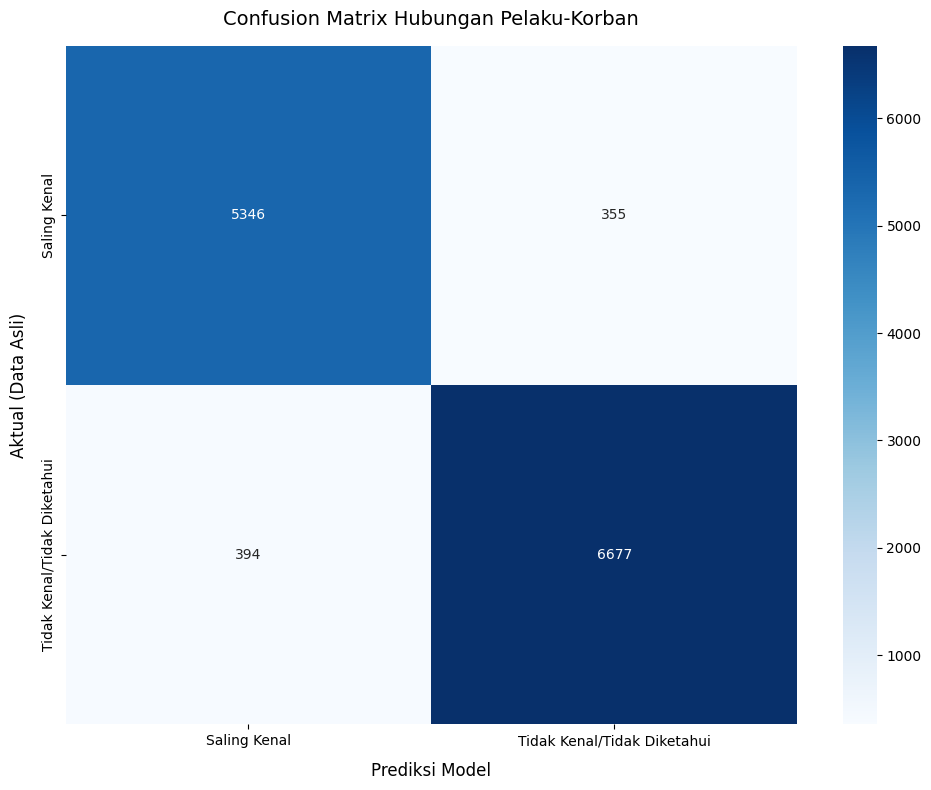


ANGKA CONFUSION MATRIX:

Data Asli [Saling Kenal] didistribusikan ke prediksi:
  -> Ditebak Saling Kenal: 5346
  -> Ditebak Tidak Kenal/Tidak Diketahui: 355

Data Asli [Tidak Kenal/Tidak Diketahui] didistribusikan ke prediksi:
  -> Ditebak Saling Kenal: 394
  -> Ditebak Tidak Kenal/Tidak Diketahui: 6677


In [10]:
print(classification_report(y_test, pred_test_gini, target_names=URUTAN_KELAS))
cm = confusion_matrix(y_test, pred_test_gini, labels=URUTAN_KELAS)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=URUTAN_KELAS,
    yticklabels=URUTAN_KELAS
)

plt.title('Confusion Matrix Hubungan Pelaku-Korban', fontsize=14, pad=15)
plt.xlabel('Prediksi Model', fontsize=12, labelpad=10)
plt.ylabel('Aktual (Data Asli)', fontsize=12, labelpad=10)
plt.tight_layout()
plt.show()

print("\nANGKA CONFUSION MATRIX:")
for i, kelas_asli in enumerate(URUTAN_KELAS):
    print(f"\nData Asli [{kelas_asli}] didistribusikan ke prediksi:")
    for j, kelas_pred in enumerate(URUTAN_KELAS):
        if cm[i][j] > 0: 
            print(f"  -> Ditebak {kelas_pred}: {cm[i][j]}")

In [11]:
df_hasil_hubungan = df.copy()

X_clean_tfidf = tfidf.transform(df_hasil_hubungan['text_clean'])
prediksi_hubungan = model_gini.predict(X_clean_tfidf)
df_hasil_hubungan['prediksi_hubungan_dt'] = prediksi_hubungan

nama_file_final = "data_hubunganpelakukorban.csv"
df_hasil_hubungan.to_csv(nama_file_final, index=False)